# Goalkeepers - 2025/26 National League

Did Collin Andeng-Ndi excel at anything last season? Every keeper in the division is measured
the same way - shot stopping by distance, by chance quality and by where the shot went, then
distribution by length and type - and Andeng-Ndi is picked out against the rest.

The data comes from `wyscout.data.goalkeeping`, which reads both teams' events for every league
match of the season (play-offs left out). The charts are drawn here in the notebook.

**The key measure is goals prevented**: post-shot xG (how likely a shot on target was to go in,
from where it was placed) minus the goals actually conceded. Above zero means the keeper kept
out more than an average keeper would have. Save % on its own is unfair on keepers who face
harder shots; goals prevented allows for that.

## Setup

Reload the `wyscout` package on every cell so edits to it are picked up without restarting the kernel, then load the API credentials and point at the local cache. Nothing here produces output.

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
from dotenv import load_dotenv

load_dotenv()  # CLIENT_ID and CLIENT_SECRET for the Wyscout API, from notebooks/.env
os.environ.setdefault("MONGO_HOST", "localhost")  # every API response is cached in Mongo

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 160)

## IDs, the keeper and the season

Andeng-Ndi is looked up in the Southend squad by name, so his id does not need to be in
`wyscout.ids`. `MIN_MINUTES` is the cut for the league comparisons - 900 minutes is ten full
matches, enough that one or two bad games do not decide the numbers.

In [3]:
from wyscout.ids import SOUTHEND, SEASON_2025
from wyscout.data.player import find_player, full_name, squad
from wyscout.data.season import season_label

SEASON = SEASON_2025
MIN_MINUTES = 900

keeper = find_player(squad(SOUTHEND, SEASON), "Andeng")
KEEPER = keeper["wyId"]
NAME = full_name(keeper)
print(KEEPER, NAME, keeper["role"]["name"], season_label(SEASON))

775220 Collin Andeng Ndi Goalkeeper 2025/26


## The whole division's season

`Season` fetches every league match once (the first run is a few hundred requests; after that it
comes from the cache) and the four tables are built from it:

* `minutes` - each keeper's league starts and minutes, from the lineups and substitutions
* `shots` - every attempt in the division, credited to the keeper who faced it, with distance,
  xG, post-shot xG, where in the goal it went and the outcome
* `passes` - every pass a keeper played, with its length, type and whether it found a team mate
* `actions` - keepers coming off their line, and their aerial duels

In [4]:
from wyscout.data.goalkeeping import Season

season = Season(SEASON)
minutes = season.keeper_minutes()
shots = season.shots_faced()
passes = season.keeper_passes()
actions = season.keeper_actions()

print(f"{len(season.matches)} league matches, {len(shots)} attempts, {len(passes)} keeper passes")
print(f"{len(season.missing)} played matches have no Wyscout events and are left out, including:")
for m in season.missing:
    if "Southend" in m["label"]:
        print("  ", m["date"][:10], m["label"])
minutes[minutes["keeper_id"] == KEEPER]

532 league matches, 12816 attempts, 39775 keeper passes
19 played matches have no Wyscout events and are left out, including:
   2025-12-20 Tamworth - Southend United, 2-1


,keeper_id,keeper,team_id,team,matches,starts,minutes
14,775220,C. Andeng Ndi,1687,Southend United,33,32,2963


## Every regular keeper, side by side

One row per keeper with at least `MIN_MINUTES`, sorted by goals prevented. Andeng-Ndi's row is
highlighted. Columns:

* **save %** - saves over shots on target; **np** = with penalties taken out
* **post-shot xG** - the goals an average keeper would have conceded from the shots on target faced
* **goals prevented** - post-shot xG minus goals conceded, in total and per 90
* **PSxG/SoT** - post-shot xG per shot on target: how hard the shots faced were
* **pass %**, **short %**, **long %**, **60 m+ %** - distribution completion overall, under 20 m, over 40 m and over 60 m
* **exits/90** - times off the line per 90 minutes

In [5]:
from wyscout.data.goalkeeping import keeper_table

table = keeper_table(shots, passes, actions, minutes, min_minutes=MIN_MINUTES)
table.index = table.index + 1
COLUMNS = {
    "keeper": "keeper", "team": "team", "minutes": "mins", "goals_conceded": "conceded",
    "save_pct": "save %", "np_save_pct": "np save %", "post_shot_xG": "post-shot xG",
    "goals_prevented": "goals prevented", "goals_prevented_90": "GP/90", "psxg_per_sot": "PSxG/SoT",
    "on_target_faced_90": "SoT faced/90", "pass_pct": "pass %", "short_pass_pct": "short %",
    "long_pass_pct": "long %", "very_long_pass_pct": "60 m+ %", "long_share": "long share", "exits_90": "exits/90",
}
pct = ["save %", "np save %", "pass %", "short %", "long %", "60 m+ %", "long share"]
(
    table[list(COLUMNS)].rename(columns=COLUMNS)
    .style.format({c: "{:.0%}" for c in pct} | {"post-shot xG": "{:.1f}", "goals prevented": "{:+.1f}",
                   "GP/90": "{:+.2f}", "PSxG/SoT": "{:.2f}", "SoT faced/90": "{:.1f}", "exits/90": "{:.2f}"})
    .apply(lambda r: ["background-color: #dbe9f6; font-weight: bold" if table.loc[r.name, "keeper_id"] == KEEPER
                      else "" for _ in r], axis=1)
    .background_gradient(subset=["goals prevented"], cmap="RdYlGn", vmin=-8, vmax=8)
)

,keeper,team,mins,conceded,save %,np save %,post-shot xG,goals prevented,GP/90,PSxG/SoT,SoT faced/90,pass %,short %,long %,60 m+ %,long share,exits/90
1,M. Terry,Braintree Town,3330,57,77%,79%,73.6,+16.6,+0.45,0.30,6.6,83%,98%,76%,58%,61%,1.70
2,H. Cartwright,Hartlepool United,1118,5,91%,91%,15.9,+10.9,+0.88,0.27,4.7,80%,99%,69%,55%,60%,2.33
3,J. Ward,Yeovil Town,4051,65,71%,73%,74.2,+9.2,+0.20,0.33,5.0,81%,99%,64%,56%,48%,1.96
4,W. Jääskeläinen,Woking,3240,36,72%,73%,45.0,+9.0,+0.25,0.35,3.6,81%,99%,68%,70%,56%,2.08
5,L. Walker,Solihull Moors,4098,71,70%,71%,78.2,+7.2,+0.16,0.33,5.2,80%,98%,69%,63%,56%,1.73
6,T. Brooks,Gateshead,2024,55,68%,69%,62.1,+7.1,+0.32,0.36,7.6,81%,98%,57%,47%,41%,2.05
7,A. Desbois,Gateshead,1080,10,82%,82%,15.2,+5.2,+0.44,0.27,4.8,70%,99%,56%,48%,62%,2.75
8,L. Hutchinson,Altrincham,3869,54,76%,76%,59.0,+5.0,+0.12,0.26,5.2,83%,98%,65%,53%,38%,1.33
9,H. Male,York City,4140,41,73%,74%,45.8,+4.8,+0.10,0.30,3.3,82%,99%,54%,39%,33%,0.80
10,F. Herrick,Boreham Wood,900,7,78%,80%,11.3,+4.3,+0.43,0.35,3.2,82%,99%,51%,40%,28%,2.50


## Chart helpers

A single colour for Andeng-Ndi and grey for everyone else, used by every chart below.
`spread` is the main comparison chart: for each group (a distance band, an xG band...) every
qualifying keeper is a grey dot, the league as a whole is a black bar and Andeng-Ndi is the blue
diamond. Where he sits in the cloud of dots is how he ranks for that kind of shot.

In [6]:
from wyscout.viz.consts import GRID, MUTED, NAVY, TEXT, THIS_COL

HIGHLIGHT = THIS_COL
OTHERS = "#b8c2cc"
REGULARS = table["keeper_id"].tolist()


def spread(ax, per_keeper, league, column, value, title, fmt="{:.0%}", ylabel=None, reference=None):
    """Grey dot per keeper, black bar for the league, blue diamond for KEEPER, one column per group."""
    groups = list(league[column])
    x = {g: i for i, g in enumerate(groups)}
    rng = np.random.default_rng(1)
    others = per_keeper[per_keeper["keeper_id"] != KEEPER]
    ax.scatter([x[g] + rng.uniform(-0.18, 0.18) for g in others[column]], others[value],
               s=28, color=OTHERS, alpha=0.9, zorder=2, label="Other regular keepers")
    ax.scatter(league[column].map(x), league[value], marker="_", s=900, linewidth=2.5, color=TEXT,
               zorder=3, label="League as a whole")
    mine = per_keeper[per_keeper["keeper_id"] == KEEPER]
    ax.scatter(mine[column].map(x), mine[value], marker="D", s=110, color=HIGHLIGHT, edgecolor="white",
               linewidth=1.2, zorder=4, label=NAME)
    for _, r in mine.iterrows():
        ax.annotate(fmt.format(r[value]), (x[r[column]], r[value]), xytext=(12, 0), textcoords="offset points",
                    va="center", fontsize=10, color=HIGHLIGHT, weight="bold")
    if reference is not None:
        ax.axhline(reference, color=MUTED, linewidth=1, linestyle=":")
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(groups)
    ax.set_title(title, loc="left", fontsize=13, color=TEXT, weight="bold")
    ax.set_ylabel(ylabel or value)
    ax.grid(axis="y", color=GRID)
    ax.grid(axis="x", visible=False)
    ax.spines[["top", "right"]].set_visible(False)


def rank_of(df, column, higher_is_better=True):
    """KEEPER's rank in df by column, as "3rd of 24"."""
    ranks = df[column].rank(ascending=not higher_is_better, method="min")
    rank = int(ranks[df["keeper_id"] == KEEPER].iloc[0])
    suffix = "th" if 10 <= rank % 100 <= 20 else {1: "st", 2: "nd", 3: "rd"}.get(rank % 10, "th")
    return f"{rank}{suffix} of {len(df)}"

## Shot stopping overall

**Visualisation:** each bar is a regular keeper's goals prevented over the season, best at the
top; Andeng-Ndi is in blue. On the right, the same keepers by how hard the shots they faced
were (post-shot xG per shot on target) against their save % - a keeper above the dashed line
saved more than the shots they faced would predict.

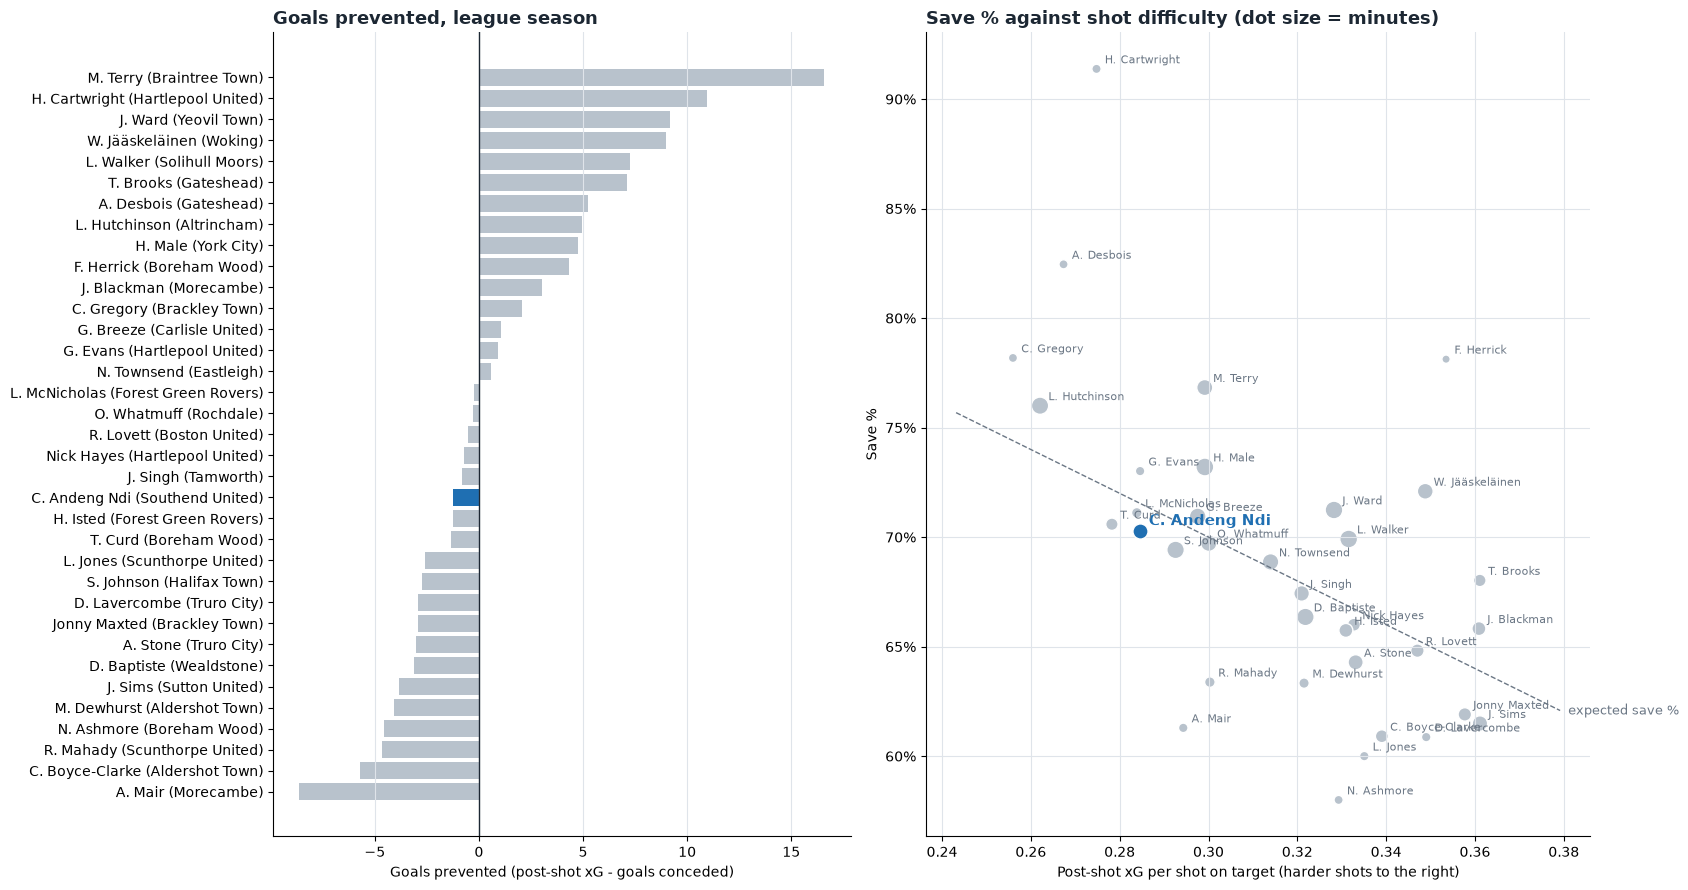

Collin Andeng Ndi: -1.2 goals prevented (21st of 35), save % 70% (14th of 35), PSxG per SoT 0.28 (28th of 35 for hardest shots faced)


In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 9), gridspec_kw={"width_ratios": [1, 1.15]})

ordered = table.sort_values("goals_prevented")
colours = [HIGHLIGHT if k == KEEPER else OTHERS for k in ordered["keeper_id"]]
ax1.barh(ordered["keeper"] + " (" + ordered["team"] + ")", ordered["goals_prevented"], color=colours)
ax1.axvline(0, color=TEXT, linewidth=1)
ax1.set_xlabel("Goals prevented (post-shot xG - goals conceded)")
ax1.set_title("Goals prevented, league season", loc="left", fontsize=13, weight="bold", color=TEXT)
ax1.spines[["top", "right"]].set_visible(False)
ax1.grid(axis="x", color=GRID)

others = table[table["keeper_id"] != KEEPER]
mine = table[table["keeper_id"] == KEEPER]
ax2.scatter(others["psxg_per_sot"], others["save_pct"], s=others["minutes"] / 25, color=OTHERS, edgecolor="white")
ax2.scatter(mine["psxg_per_sot"], mine["save_pct"], s=mine["minutes"] / 25, color=HIGHLIGHT, edgecolor="white", zorder=3)
for _, r in table.iterrows():
    ax2.annotate(r["keeper"], (r["psxg_per_sot"], r["save_pct"]), xytext=(6, 4), textcoords="offset points",
                 fontsize=8 if r["keeper_id"] != KEEPER else 11, color=MUTED if r["keeper_id"] != KEEPER else HIGHLIGHT,
                 weight="normal" if r["keeper_id"] != KEEPER else "bold")
xs = np.linspace(table["psxg_per_sot"].min() * 0.95, table["psxg_per_sot"].max() * 1.05, 10)
ax2.plot(xs, 1 - xs, color=MUTED, linestyle="--", linewidth=1)
ax2.text(xs[-1], 1 - xs[-1], "  expected save %", color=MUTED, va="center", fontsize=9)
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_xlabel("Post-shot xG per shot on target (harder shots to the right)")
ax2.set_ylabel("Save %")
ax2.set_title("Save % against shot difficulty (dot size = minutes)", loc="left", fontsize=13, weight="bold", color=TEXT)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(color=GRID)
plt.tight_layout()
plt.show()

r = table[table["keeper_id"] == KEEPER].iloc[0]
print(f"{NAME}: {r['goals_prevented']:+.1f} goals prevented ({rank_of(table, 'goals_prevented')}), "
      f"save % {r['save_pct']:.0%} ({rank_of(table, 'save_pct')}), "
      f"PSxG per SoT {r['psxg_per_sot']:.2f} ({rank_of(table, 'psxg_per_sot')} for hardest shots faced)")

## Where he ranks - percentile profile

**Visualisation:** a pizza chart of Andeng-Ndi's percentile among the regular keepers in each
measure - 100 is the best in the league, 50 the middle. Shot stopping is blue, distribution
green and work off the line gold. A long slice is a strength. "Fewer SoT faced" is about the
defence in front of him rather than the keeper, so it is left out.

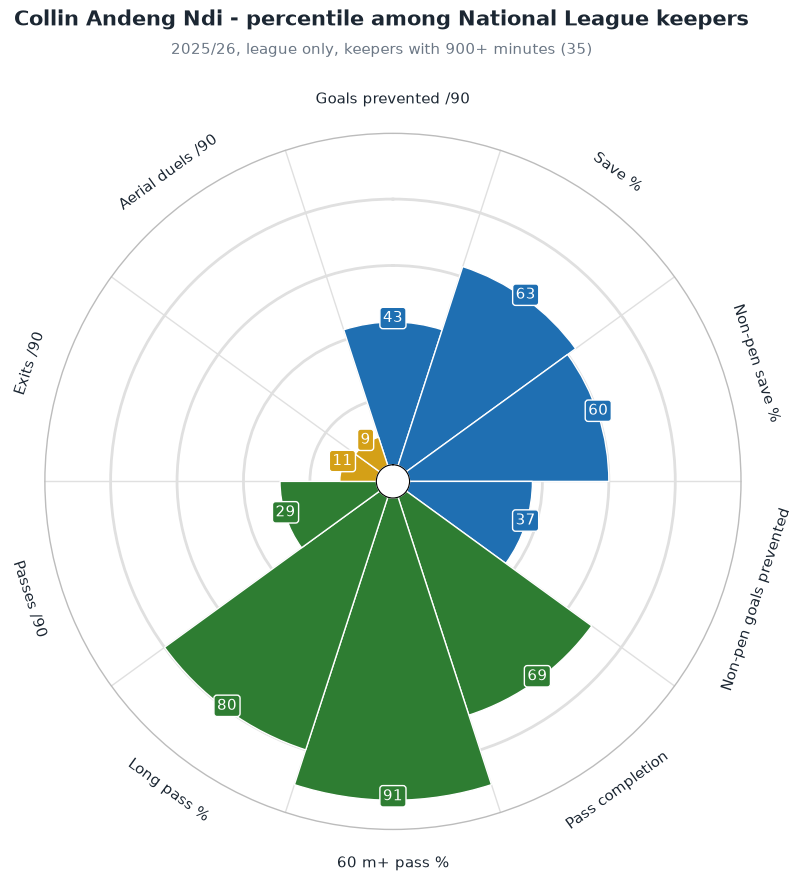

,keeper,team,goals_prevented_90,save_pct,np_save_pct,np_goals_prevented,pass_pct,very_long_pass_pct,long_pass_pct,passes_90,exits_90,aerials_90
21,C. Andeng Ndi,Southend United,43.0,63.0,60.0,37.0,69.0,91.0,80.0,29.0,11.0,9.0


In [8]:
from mplsoccer import PyPizza
from wyscout.data.goalkeeping import percentile_ranks

PROFILE = {
    "goals_prevented_90": ("Goals prevented /90", True, "shot"),
    "save_pct": ("Save %", True, "shot"),
    "np_save_pct": ("Non-pen save %", True, "shot"),
    "np_goals_prevented": ("Non-pen goals prevented", True, "shot"),
    "pass_pct": ("Pass completion", True, "pass"),
    "very_long_pass_pct": ("60 m+ pass %", True, "pass"),
    "long_pass_pct": ("Long pass %", True, "pass"),
    "passes_90": ("Passes /90", True, "pass"),
    "exits_90": ("Exits /90", True, "box"),
    "aerials_90": ("Aerial duels /90", True, "box"),
}
SLICE = {"shot": "#1f6fb2", "pass": "#2e7d32", "box": "#d4a017"}

ranks = percentile_ranks(table, {k: v[1] for k, v in PROFILE.items()})
values = [int(ranks.loc[ranks["keeper_id"] == KEEPER, k].iloc[0]) for k in PROFILE]

pizza = PyPizza(params=[v[0] for v in PROFILE.values()], background_color="white", straight_line_color="#e0e0e0",
                last_circle_color="#bcbcbc", other_circle_color="#e0e0e0", straight_line_lw=1, other_circle_ls="-")
fig, ax = pizza.make_pizza(
    values, figsize=(9, 9.5), param_location=110,
    slice_colors=[SLICE[v[2]] for v in PROFILE.values()],
    value_colors=["white"] * len(values), value_bck_colors=[SLICE[v[2]] for v in PROFILE.values()],
    kwargs_slices=dict(edgecolor="white", zorder=2, linewidth=1),
    kwargs_params=dict(color=TEXT, fontsize=11, va="center"),
    kwargs_values=dict(color="white", fontsize=11, zorder=3,
                       bbox=dict(edgecolor="white", boxstyle="round,pad=0.2", lw=1)),
)
fig.text(0.5, 0.975, f"{NAME} - percentile among National League keepers", ha="center", size=15, weight="bold", color=TEXT)
fig.text(0.5, 0.945, f"{season_label(SEASON)}, league only, keepers with {MIN_MINUTES}+ minutes ({len(table)})",
         ha="center", size=11, color=MUTED)
plt.show()
ranks[ranks["keeper_id"] == KEEPER].drop(columns=["keeper_id"])

## Shot stopping by distance

Shots split by how far out they were taken: inside the six-yard box, to the penalty spot, to the
edge of the box, just outside it and from long range. Penalties are left out - they all come
from 11 m and would swamp the 6-12 m band (they have their own section below).

**Visualisation:** left, save % per band; right, goals prevented per shot on target, which also
allows for how well-placed the shots were. A keeper needs at least five shots on target in a band
to be plotted - he faced too few in the six-yard box for a diamond there.

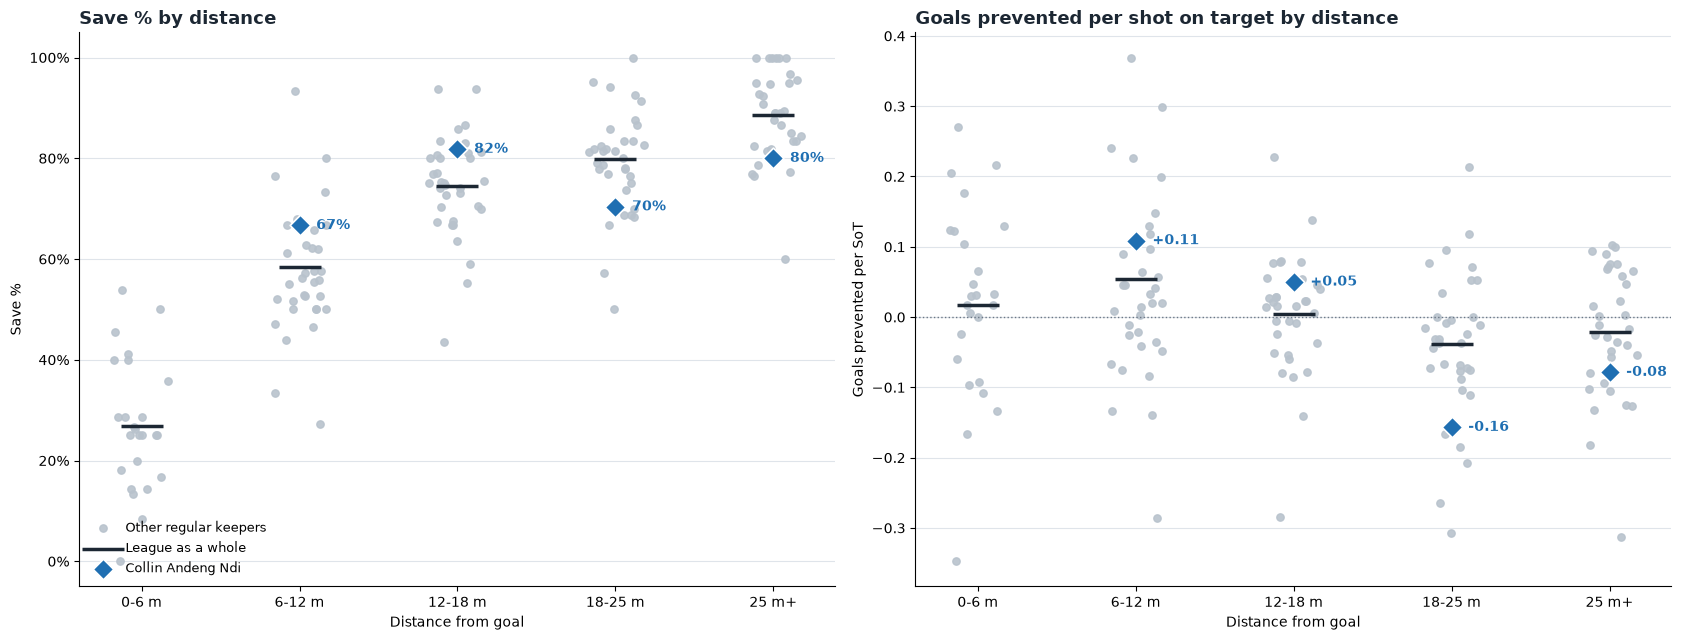

,goals_prevented (him),on_target (him),save_pct (league),save_pct (him),saves (him)
distance_band,,,,,
0-6 m,-0.63,4.0,0.27,0.25,1.0
12-18 m,1.10,22.0,0.74,0.82,18.0
18-25 m,-4.23,27.0,0.80,0.70,19.0
25 m+,-1.18,15.0,0.89,0.80,12.0
6-12 m,3.27,30.0,0.58,0.67,20.0


In [9]:
from wyscout.data.goalkeeping import keeper_split, split_by

open_play = shots[shots["kind"] != "Penalty"]


def band_charts(column, title, xlabel):
    league = split_by(open_play, column)
    league = league[league["keeper_id"] == 0].assign(gp_per_sot=lambda d: d["goals_prevented"] / d["on_target"])
    per_keeper = keeper_split(open_play, column, REGULARS)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5))
    spread(ax1, per_keeper, league, column, "save_pct", f"Save % by {title}", ylabel="Save %")
    ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
    spread(ax2, per_keeper, league, column, "gp_per_sot", f"Goals prevented per shot on target by {title}",
           fmt="{:+.2f}", ylabel="Goals prevented per SoT", reference=0)
    for ax in (ax1, ax2):
        ax.set_xlabel(xlabel)
    ax1.legend(loc="lower left", frameon=False, fontsize=9)
    plt.tight_layout()
    plt.show()

    mine = split_by(open_play, column, [KEEPER])
    out = mine.pivot_table(index=column, columns="keeper_id", values=["on_target", "saves", "save_pct", "goals_prevented"],
                           observed=False)
    out.columns = [f"{v} ({'league' if k == 0 else 'him'})" for v, k in out.columns]
    return out[[c for c in out.columns if "league" not in c or "save_pct" in c]].round(2)


band_charts("distance_band", "distance", "Distance from goal")

## Shot stopping by chance quality

The same view split by pre-shot xG - how good the chance was before the ball was struck. Low xG
is a speculative shot; 0.30+ is a big chance. Saves against big chances are where a keeper wins
points; letting in low-xG shots is where they lose them.

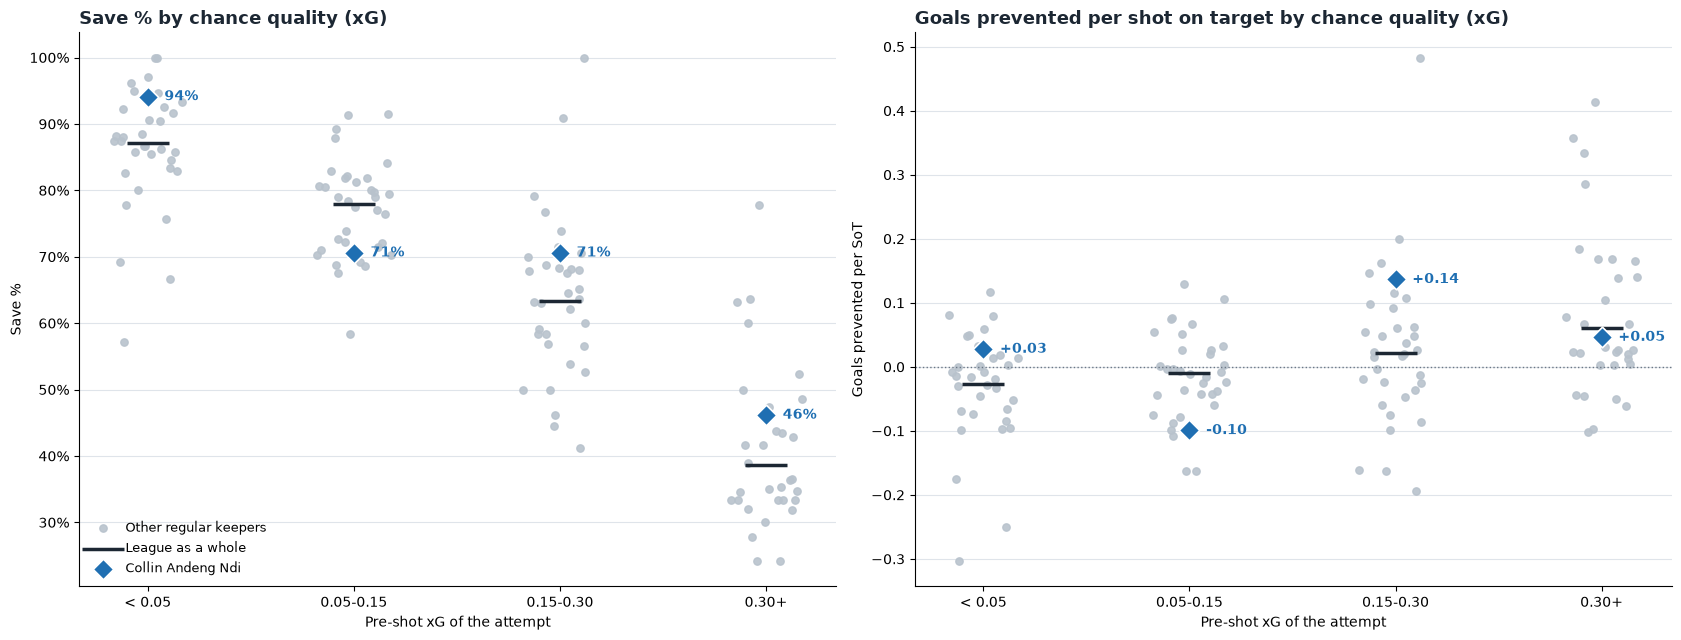

,goals_prevented (him),on_target (him),save_pct (league),save_pct (him),saves (him)
xg_band,,,,,
0.05-0.15,-5.07,51.0,0.78,0.71,36.0
0.15-0.30,2.32,17.0,0.63,0.71,12.0
0.30+,0.60,13.0,0.39,0.46,6.0
< 0.05,0.47,17.0,0.87,0.94,16.0


In [10]:
band_charts("xg_band", "chance quality (xG)", "Pre-shot xG of the attempt")

## By type of shot

Headers against shots with the feet, and how the chance arose (open play, counter-attack, from a
corner or free kick...). Bands with fewer than five shots on target for a keeper are left out.

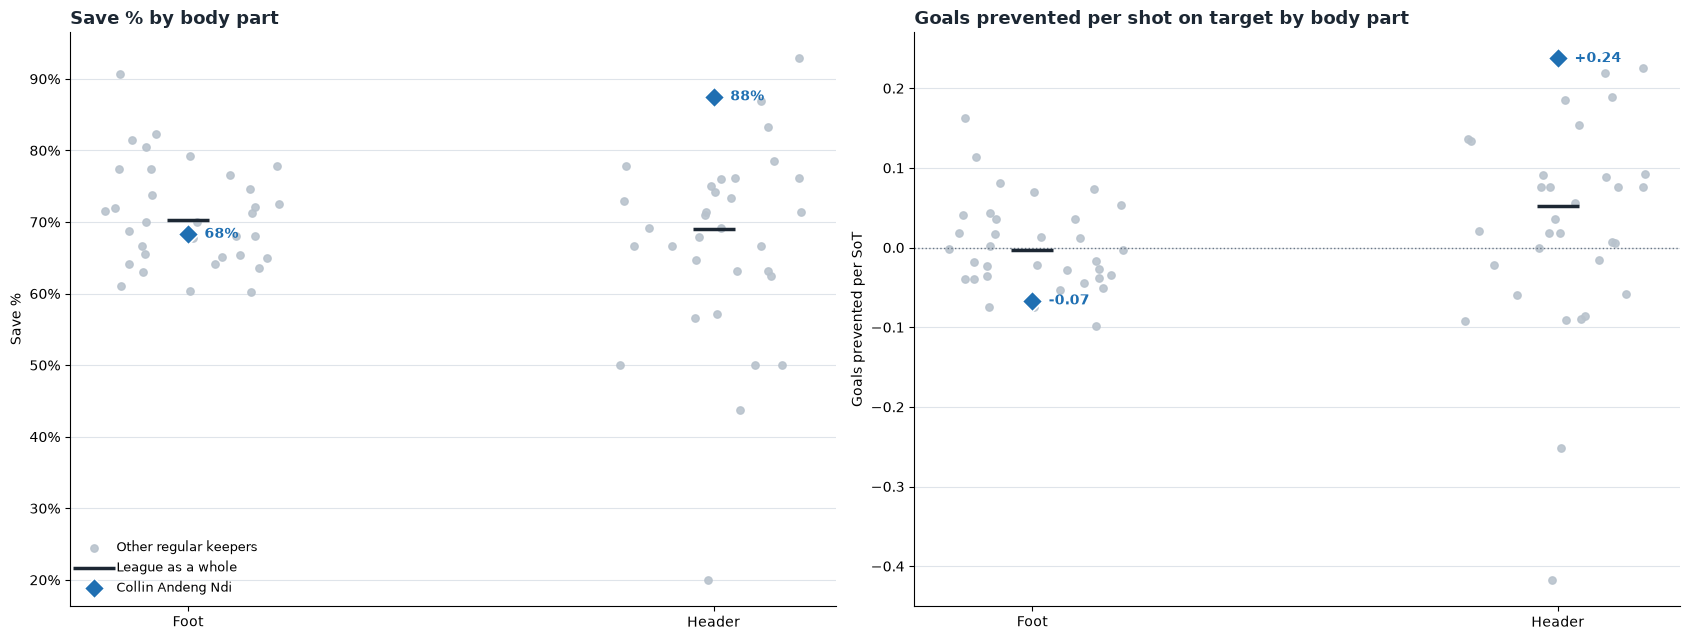

,goals_prevented (him),on_target (him),save_pct (league),save_pct (him),saves (him)
header,,,,,
Foot,-5.48,82.0,0.70,0.68,56.0
Header,3.80,16.0,0.69,0.88,14.0


In [11]:
open_play = open_play.assign(header=np.where(open_play["body_part"] == "Header", "Header", "Foot"))
band_charts("header", "body part", "")

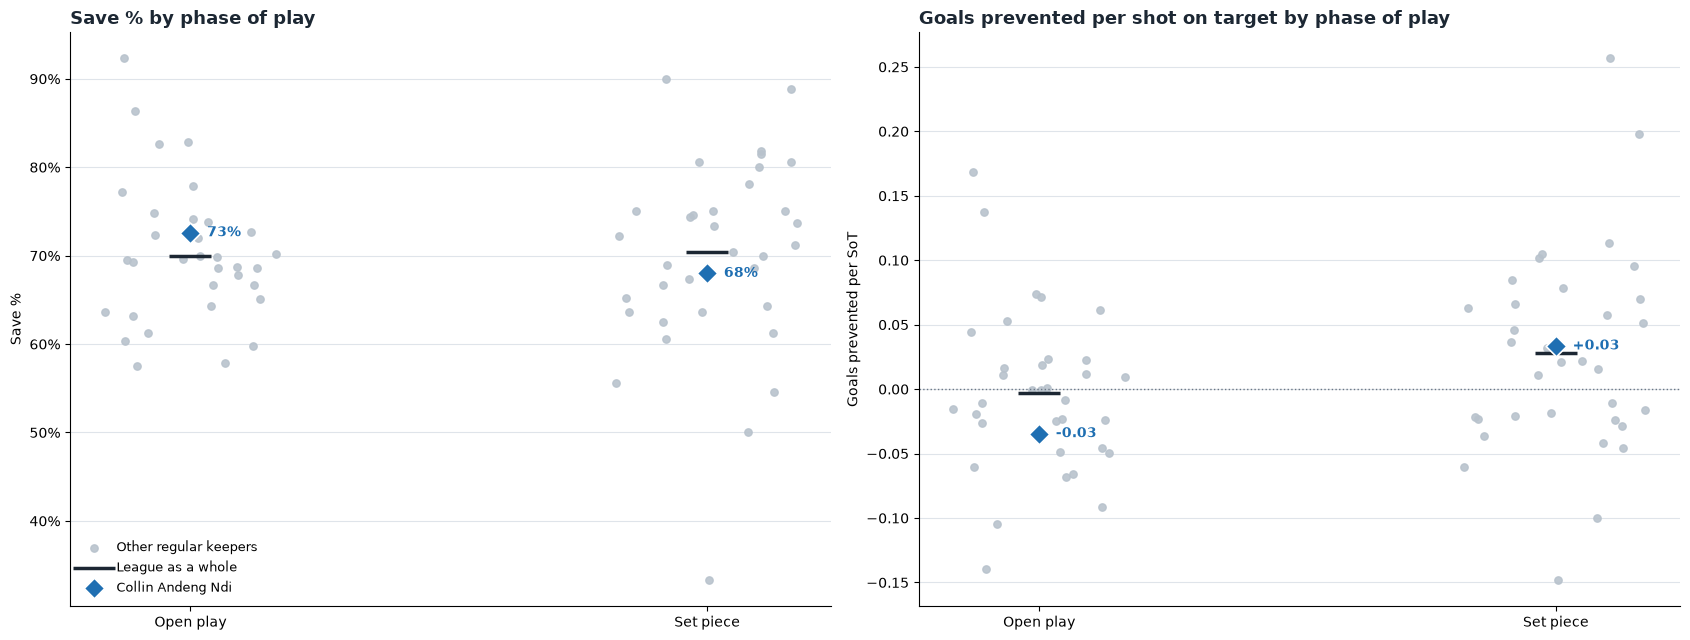

,goals_prevented (him),on_target (him),save_pct (league),save_pct (him),saves (him)
phase,,,,,
Open play,-2.52,73.0,0.7,0.73,53.0
Set piece,0.84,25.0,0.7,0.68,17.0


In [12]:
open_play = open_play.assign(phase=np.where(open_play["situation"].isin(["Open play", "Counter-attack"]),
                                            "Open play", "Set piece"))
band_charts("phase", "phase of play", "")

## Where the shots went

Every on-target attempt has a goal zone - top/middle/bottom and left/centre/right, seen from the
shooter. **Visualisation:** the goal split into nine, each cell showing Andeng-Ndi's save %
and the shots he faced there, coloured by the difference from the league's save % in that cell
(green better, red worse). Penalties left out.

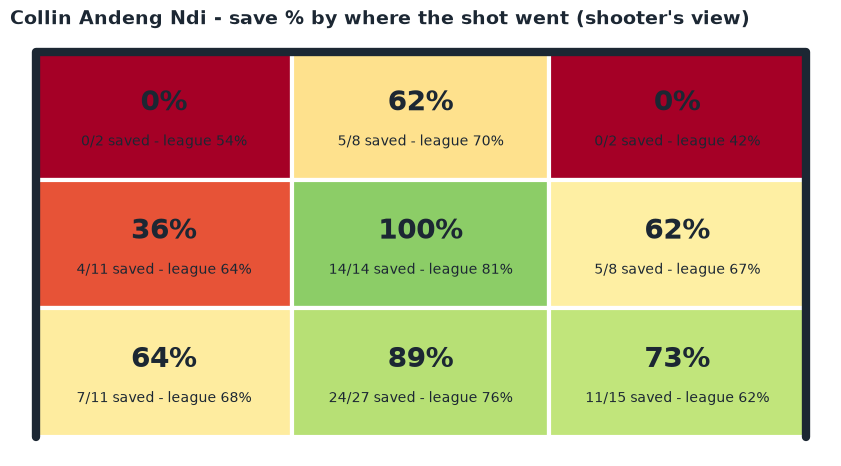

him                league               
              sot saves save_pct    sot saves save_pct
height side                                           
bottom centre  27    24     0.89   1176   889     0.76
       left    11     7     0.64    677   463     0.68
       right   15    11     0.73    606   374     0.62
middle centre  14    14     1.00    881   713     0.81
       left    11     4     0.36    418   266     0.64
       right    8     5     0.62    415   277     0.67
top    centre   8     5     0.62    299   210     0.70
       left     2     0     0.00    136    74     0.54
       right    2     0     0.00    133    56     0.42

In [13]:
from matplotlib.colors import TwoSlopeNorm
from matplotlib.patches import Rectangle

on_target = open_play[open_play["on_target"]]
HEIGHTS, SIDES = ["top", "middle", "bottom"], ["left", "centre", "right"]


def zone_grid(pool):
    g = pool.groupby(["height", "side"]).agg(sot=("save", "size"), saves=("save", "sum"))
    g["save_pct"] = g["saves"] / g["sot"]
    return g


league_zone = zone_grid(on_target)
mine_zone = zone_grid(on_target[on_target["keeper_id"] == KEEPER])

fig, ax = plt.subplots(figsize=(12, 5.5))
norm = TwoSlopeNorm(vcenter=0, vmin=-0.4, vmax=0.4)
cmap = plt.get_cmap("RdYlGn")
for i, h in enumerate(HEIGHTS):
    for j, s in enumerate(SIDES):
        lg = league_zone.loc[(h, s)] if (h, s) in league_zone.index else None
        me = mine_zone.loc[(h, s)] if (h, s) in mine_zone.index else None
        if me is None or lg is None:
            ax.add_patch(Rectangle((j, 2 - i), 1, 1, facecolor="#f2f2f2", edgecolor="white", linewidth=3))
            continue
        diff = me["save_pct"] - lg["save_pct"]
        ax.add_patch(Rectangle((j, 2 - i), 1, 1, facecolor=cmap(norm(diff)), edgecolor="white", linewidth=3))
        ax.text(j + 0.5, 2 - i + 0.6, f"{me['save_pct']:.0%}", ha="center", va="center", fontsize=20, weight="bold", color=TEXT)
        ax.text(j + 0.5, 2 - i + 0.3, f"{int(me['saves'])}/{int(me['sot'])} saved - league {lg['save_pct']:.0%}",
                ha="center", va="center", fontsize=10, color=TEXT)
ax.plot([0, 0, 3, 3], [0, 3, 3, 0], color=TEXT, linewidth=6, solid_capstyle="round")
ax.set_xlim(-0.1, 3.1)
ax.set_ylim(-0.15, 3.15)
ax.set_aspect(0.5)
ax.axis("off")
ax.set_title(f"{NAME} - save % by where the shot went (shooter's view)", loc="left", fontsize=14, weight="bold", color=TEXT)
plt.show()

pd.concat({"him": mine_zone, "league": league_zone}, axis=1).round(2)

## Shots faced, on the pitch

**Visualisation:** every on-target attempt Andeng-Ndi faced, from where it was struck. Blue dots
are saves, red are goals; the size is the post-shot xG (how likely the shot was to go in). Large
blue dots are the hard saves; small red dots are the ones he would want back.

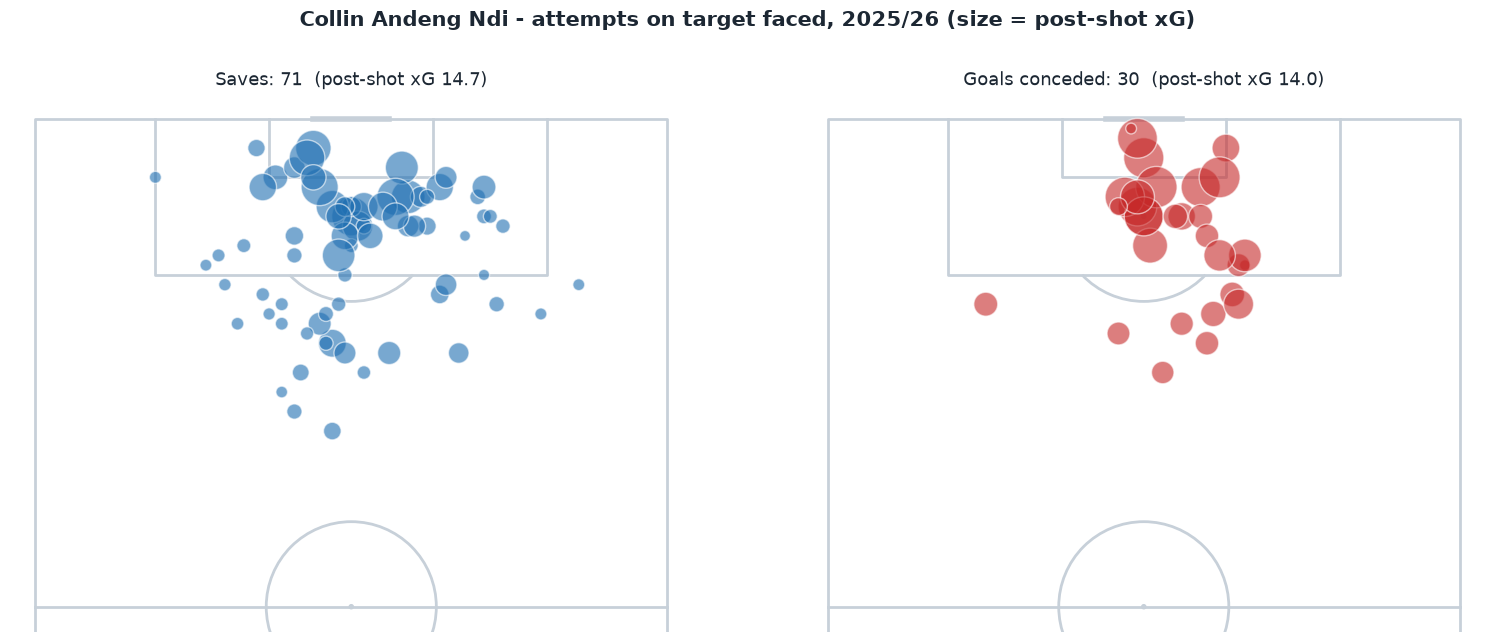

Best saves (highest post-shot xG kept out)


,date,shooter,minute,distance_m,xG,post_shot_xG,kind
409,2025-08-16,T. Tonks,6,10.5,0.7600,0.8100,Penalty
12222,2026-04-14,C. Warren,85,9.7,0.1557,0.7294,Shot
2897,2025-09-24,H. Saunders,47,8.1,0.3701,0.7264,Shot
7379,2026-01-17,J. Stones,53,6.3,0.2788,0.6653,Shot
4018,2025-10-18,E. Dixon-Bonner,56,5.2,0.4814,0.6579,Shot


Softest goals (lowest post-shot xG conceded)


,date,shooter,minute,distance_m,xG,post_shot_xG,kind
1128,2025-08-25,N. Sheron,65,19.1,0.06446,0.0000,Shot
7777,2026-01-27,H. Gilmour,89,1.7,0.57720,0.0000,Shot
10063,2026-03-10,Brad Nicholson,44,9.8,0.10410,0.1157,Shot
1281,2025-08-30,D. Creaney,52,27.4,0.05339,0.2232,Shot
12282,2026-04-18,K. Morris,84,23.3,0.07036,0.2348,Shot


In [14]:
from mplsoccer import VerticalPitch

faced = shots[(shots["keeper_id"] == KEEPER) & shots["on_target"]]
pitch = VerticalPitch(pitch_type="wyscout", half=True, pitch_color="white", line_color="#c7d0d9")
fig, axs = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, (label, part, colour) in zip(axs, [("Saves", faced[faced["save"]], HIGHLIGHT),
                                          ("Goals conceded", faced[faced["goal"]], "#c62828")]):
    pitch.draw(ax=ax)
    pitch.scatter(part["x"], part["y"], s=60 + part["post_shot_xG"] * 900, color=colour, alpha=0.6,
                  edgecolor="white", ax=ax)
    ax.set_title(f"{label}: {len(part)}  (post-shot xG {part['post_shot_xG'].sum():.1f})", fontsize=13, color=TEXT)
fig.suptitle(f"{NAME} - attempts on target faced, {season_label(SEASON)} (size = post-shot xG)",
             fontsize=15, weight="bold", color=TEXT)
plt.tight_layout(rect=(0, 0, 1, 0.93))
plt.show()

print("Best saves (highest post-shot xG kept out)")
display(faced[faced["save"]].nlargest(5, "post_shot_xG")[["date", "shooter", "minute", "distance_m", "xG", "post_shot_xG", "kind"]])
print("Softest goals (lowest post-shot xG conceded)")
display(faced[faced["goal"]].nsmallest(5, "post_shot_xG")[["date", "shooter", "minute", "distance_m", "xG", "post_shot_xG", "kind"]])

## Through the season

**Visualisation:** cumulative goals prevented match by match. A rising line is a run of good
form; a sharp drop is a match where he let in shots an average keeper would usually stop.

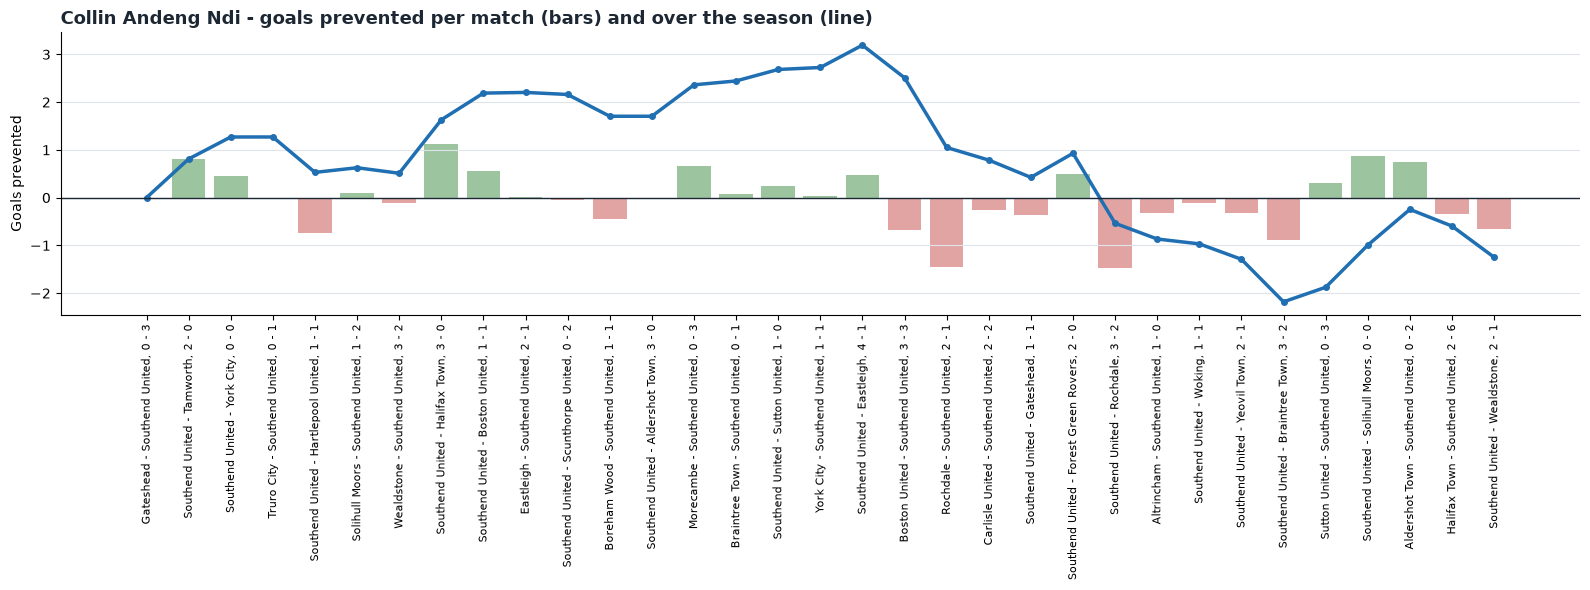

In [15]:
from wyscout.match import get_match_details

by_match = (shots[shots["keeper_id"] == KEEPER].groupby(["match_id", "date"], as_index=False)
            .agg(goals_prevented=("goals_prevented", "sum"), conceded=("goal", "sum"), sot=("on_target", "sum")))
by_match = by_match.sort_values("date").reset_index(drop=True)
by_match["label"] = [get_match_details(m)["label"] for m in by_match["match_id"]]
by_match["cumulative"] = by_match["goals_prevented"].cumsum()

fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(by_match.index, by_match["goals_prevented"], color=np.where(by_match["goals_prevented"] >= 0, "#9cc49e", "#e2a3a3"))
ax.plot(by_match.index, by_match["cumulative"], color=HIGHLIGHT, linewidth=2.5, marker="o", markersize=4)
ax.axhline(0, color=TEXT, linewidth=1)
ax.set_xticks(by_match.index)
ax.set_xticklabels(by_match["label"], rotation=90, fontsize=8)
ax.set_ylabel("Goals prevented")
ax.set_title(f"{NAME} - goals prevented per match (bars) and over the season (line)", loc="left",
             fontsize=13, weight="bold", color=TEXT)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color=GRID)
plt.tight_layout()
plt.show()

## Penalties

Penalties faced and saved by every regular keeper - a small sample, so treat it as a note rather
than a measure.

In [16]:
pens = (table[["keeper", "team", "pens_faced", "pens_saved"]]
        .assign(conceded=lambda d: [int(shots[(shots["keeper_id"] == k) & (shots["kind"] == "Penalty")]["goal"].sum())
                                    for k in table["keeper_id"]])
        .sort_values(["pens_saved", "pens_faced"], ascending=[False, True]))
pens.style.apply(lambda r: ["font-weight: bold; background-color: #dbe9f6" if r["keeper"] == table.loc[table["keeper_id"] == KEEPER, "keeper"].iloc[0]
                            else "" for _ in r], axis=1)

,keeper,team,pens_faced,pens_saved,conceded
11,J. Blackman,Morecambe,8,4,4
30,J. Sims,Sutton United,13,3,9
8,L. Hutchinson,Altrincham,4,2,2
6,T. Brooks,Gateshead,6,2,4
15,N. Townsend,Eastleigh,6,2,4
2,H. Cartwright,Hartlepool United,1,1,0
10,F. Herrick,Boreham Wood,2,1,1
26,D. Lavercombe,Truro City,2,1,1
21,C. Andeng Ndi,Southend United,3,1,2
33,R. Mahady,Scunthorpe United,3,1,1


## Distribution by length

Every pass a keeper played - goal kicks, free kicks, throws and passes with the feet - split by
length. **Visualisation:** left, completion % per length band (a pass is complete when it
finds a team mate); right, the share of his passes in each band against the league, which
shows how he likes to play - short and patient or long and direct.

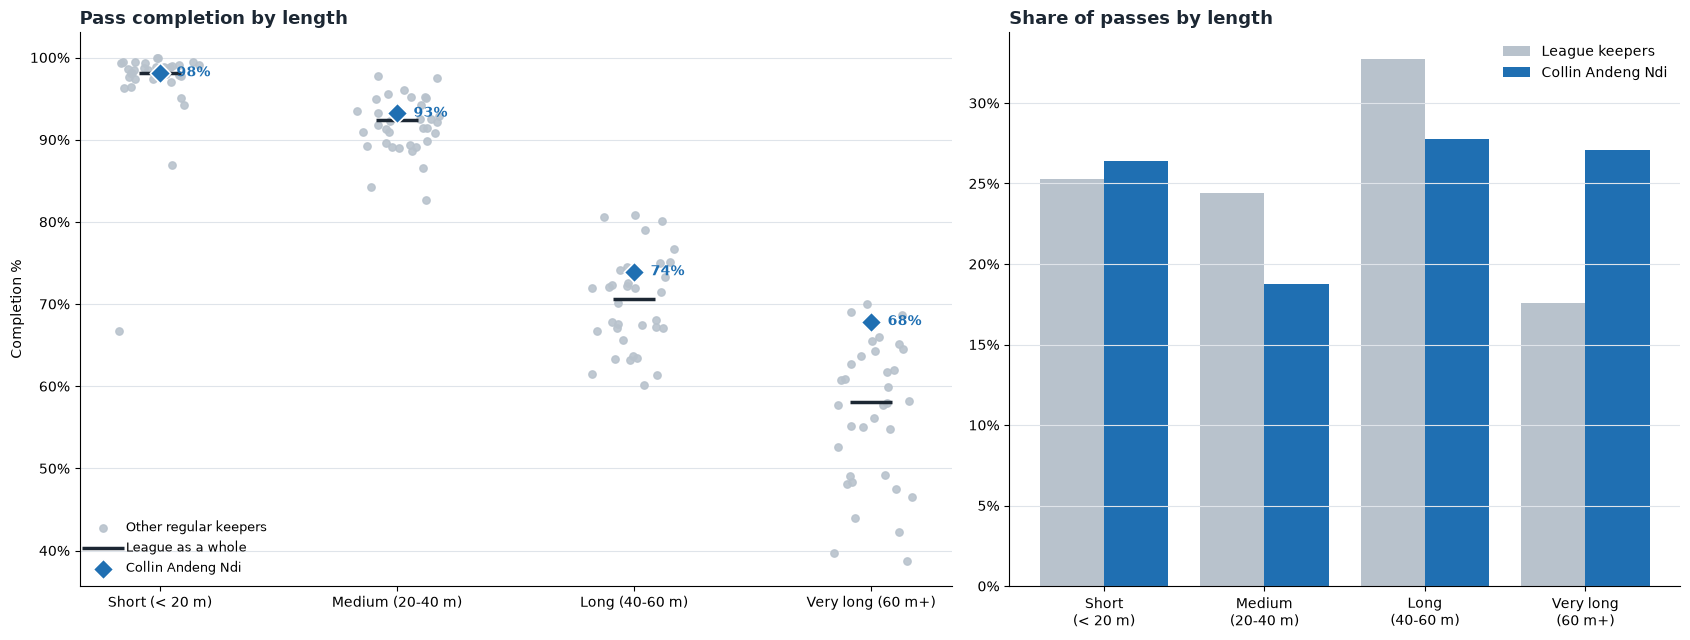

,his passes,his completion,league completion,rank
length_band,,,,
Short (< 20 m),270,98%,98%,19th of 34
Medium (20-40 m),192,93%,92%,12th of 35
Long (40-60 m),284,74%,71%,10th of 35
Very long (60 m+),277,68%,58%,4th of 35


In [17]:
from wyscout.data.goalkeeping import PASS_LABELS, pass_split

league_len = (passes.groupby("length_band", observed=False)["accurate"].mean().rename("pass_pct")
              .reset_index())
per_keeper_len = pass_split(passes, "length_band", REGULARS)

mine_passes = passes[passes["keeper_id"] == KEEPER]
regular_passes = passes[passes["keeper_id"].isin(REGULARS)]
share = pd.DataFrame({
    NAME: mine_passes["length_band"].value_counts(normalize=True),
    "League": regular_passes["length_band"].value_counts(normalize=True),
}).reindex(PASS_LABELS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [1.3, 1]})
spread(ax1, per_keeper_len, league_len, "length_band", "pass_pct", "Pass completion by length", ylabel="Completion %")
ax1.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax1.legend(loc="lower left", frameon=False, fontsize=9)

x = np.arange(len(PASS_LABELS))
ax2.bar(x - 0.2, share["League"], width=0.4, color=OTHERS, label="League keepers")
ax2.bar(x + 0.2, share[NAME], width=0.4, color=HIGHLIGHT, label=NAME)
ax2.set_xticks(x)
ax2.set_xticklabels([l.replace(" (", "\n(") for l in PASS_LABELS])
ax2.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax2.set_title("Share of passes by length", loc="left", fontsize=13, weight="bold", color=TEXT)
ax2.legend(frameon=False)
ax2.spines[["top", "right"]].set_visible(False)
ax2.grid(axis="y", color=GRID)
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "his passes": mine_passes.groupby("length_band", observed=False).size(),
    "his completion": mine_passes.groupby("length_band", observed=False)["accurate"].mean(),
    "league completion": passes.groupby("length_band", observed=False)["accurate"].mean(),
})
summary["rank"] = [rank_of(per_keeper_len[per_keeper_len["length_band"] == b], "pass_pct")
                   if (per_keeper_len["length_band"] == b).any() and KEEPER in per_keeper_len[per_keeper_len["length_band"] == b]["keeper_id"].values
                   else "" for b in summary.index]
summary.style.format({"his completion": "{:.0%}", "league completion": "{:.0%}"})

## Distribution by type

The same comparison by how the ball was played: goal kicks, free kicks, throws and kicks from
open play.

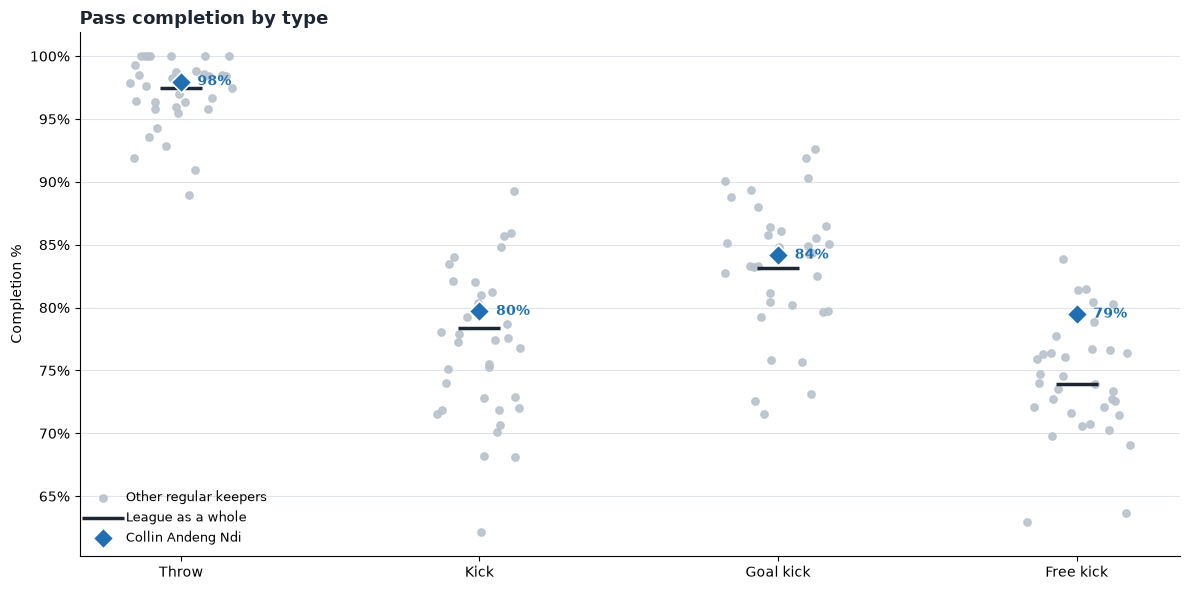

,his passes,his completion,his avg length (m),league completion,league avg length (m)
kind,,,,,
Free kick,117,79%,53,74%,50
Goal kick,196,84%,59,83%,47
Kick,611,80%,36,78%,36
Throw,99,98%,20,97%,23


In [18]:
league_kind = passes.groupby("kind")["accurate"].mean().rename("pass_pct").reset_index()
league_kind = league_kind.set_index("kind").loc[["Throw", "Kick", "Goal kick", "Free kick"]].reset_index()
per_keeper_kind = pass_split(passes, "kind", REGULARS)

fig, ax = plt.subplots(figsize=(12, 6))
spread(ax, per_keeper_kind, league_kind, "kind", "pass_pct", "Pass completion by type", ylabel="Completion %")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.legend(loc="lower left", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

kinds = pd.DataFrame({
    "his passes": mine_passes.groupby("kind").size(),
    "his completion": mine_passes.groupby("kind")["accurate"].mean(),
    "his avg length (m)": mine_passes.groupby("kind")["length_m"].mean(),
    "league completion": passes.groupby("kind")["accurate"].mean(),
    "league avg length (m)": passes.groupby("kind")["length_m"].mean(),
})
kinds.style.format({"his completion": "{:.0%}", "league completion": "{:.0%}",
                    "his avg length (m)": "{:.0f}", "league avg length (m)": "{:.0f}"})

## Where his passes went

**Visualisation:** on the left, where his passes over 40 m landed - blue complete, red
incomplete - over a heat map of where they ended. On the right the existing
`player.distribution_map`: every pass as an arrow, accurate ones in red.

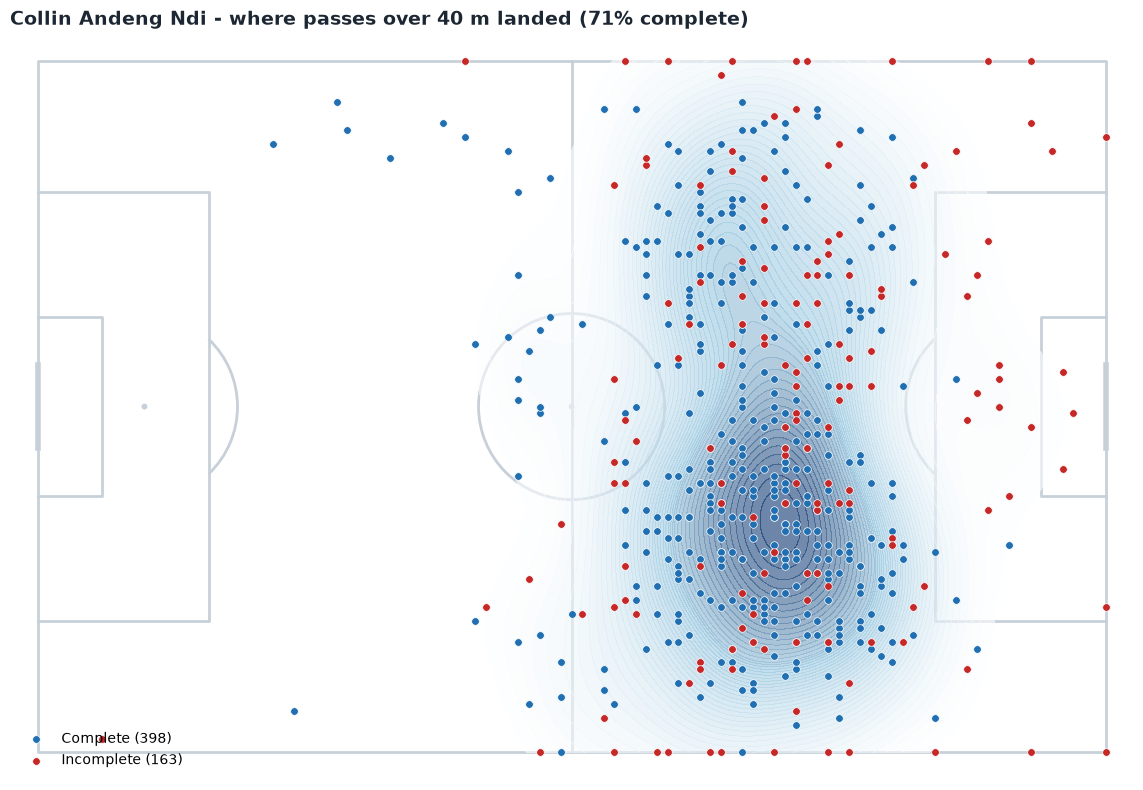

In [19]:
from matplotlib.colors import LinearSegmentedColormap
from mplsoccer import Pitch

long_passes = mine_passes[mine_passes["length_m"] >= 40]
pitch = Pitch(pitch_type="wyscout", pitch_color="white", line_color="#c7d0d9")
fig, ax = pitch.draw(figsize=(12, 8))
pitch.kdeplot(long_passes["end_x"], long_passes["end_y"], ax=ax, fill=True, levels=50, thresh=0.05,
              cmap=LinearSegmentedColormap.from_list("blues", ["white", "#9ecae1", "#08306b"]), alpha=0.6)
for ok, colour in ((True, HIGHLIGHT), (False, "#c62828")):
    part = long_passes[long_passes["accurate"] == ok]
    pitch.scatter(part["end_x"], part["end_y"], s=30, color=colour, edgecolor="white", linewidth=0.5, ax=ax,
                  label=f"{'Complete' if ok else 'Incomplete'} ({len(part)})")
ax.legend(loc="lower left", frameon=False)
ax.set_title(f"{NAME} - where passes over 40 m landed ({long_passes['accurate'].mean():.0%} complete)",
             fontsize=14, weight="bold", color=TEXT, loc="left")
plt.show()

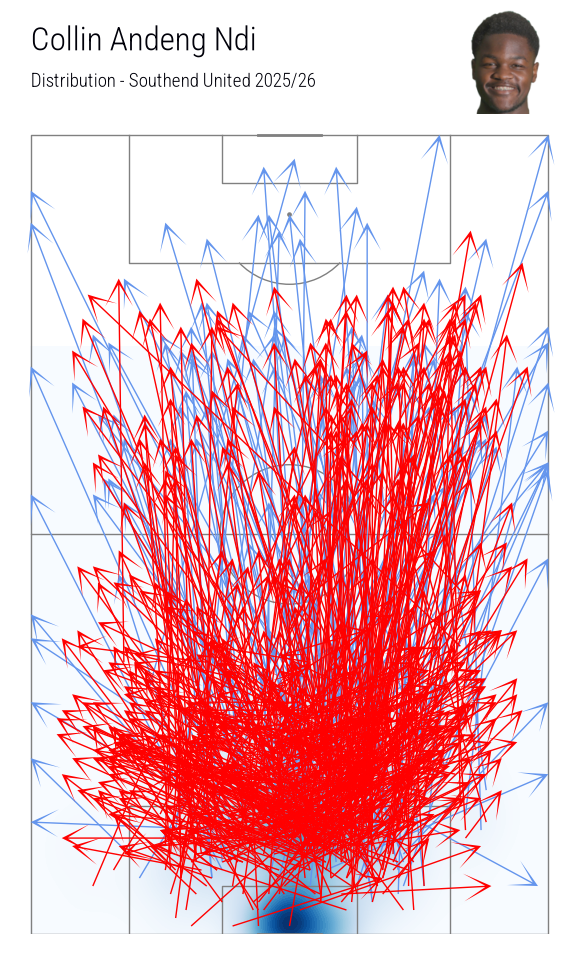

(<Figure size 635.283x1000 with 4 Axes>,
 {'pitch': <Axes: >, 'title': <Axes: >, 'endnote': <Axes: >},
 VerticalPitch(pitch_type='wyscout', half=False, pitch_color='white', line_color='grey', linewidth=1, line_zorder=2, linestyle=None, stripe=False, stripe_color='#c2d59d', stripe_zorder=0.6, pad_left=4, pad_right=4, pad_bottom=0.0, pad_top=2.5904761904761906, positional=False, positional_zorder=0.8, positional_linewidth=1, positional_linestyle=None, positional_color='#eadddd', positional_alpha=1, shade_middle=False, shade_color='#f2f2f2', shade_alpha=1, shade_zorder=0.7, pitch_length=None, pitch_width=None, goal_type='line', goal_alpha=1, line_alpha=1, label=False, tick=False, axis=False, spot_scale=0.024, spot_type='circle'), corner_arcs=False))

In [20]:
from wyscout.reports import player

player.distribution_map(KEEPER, SOUTHEND, SEASON, fig_height=10)

## Off his line

Keeper exits (coming out to sweep, claim or punch) and aerial duels per 90 minutes, against the
other regular keepers. Wyscout does not record claimed crosses separately, so this is a feel for
how active he is outside the six-yard box rather than a success rate.

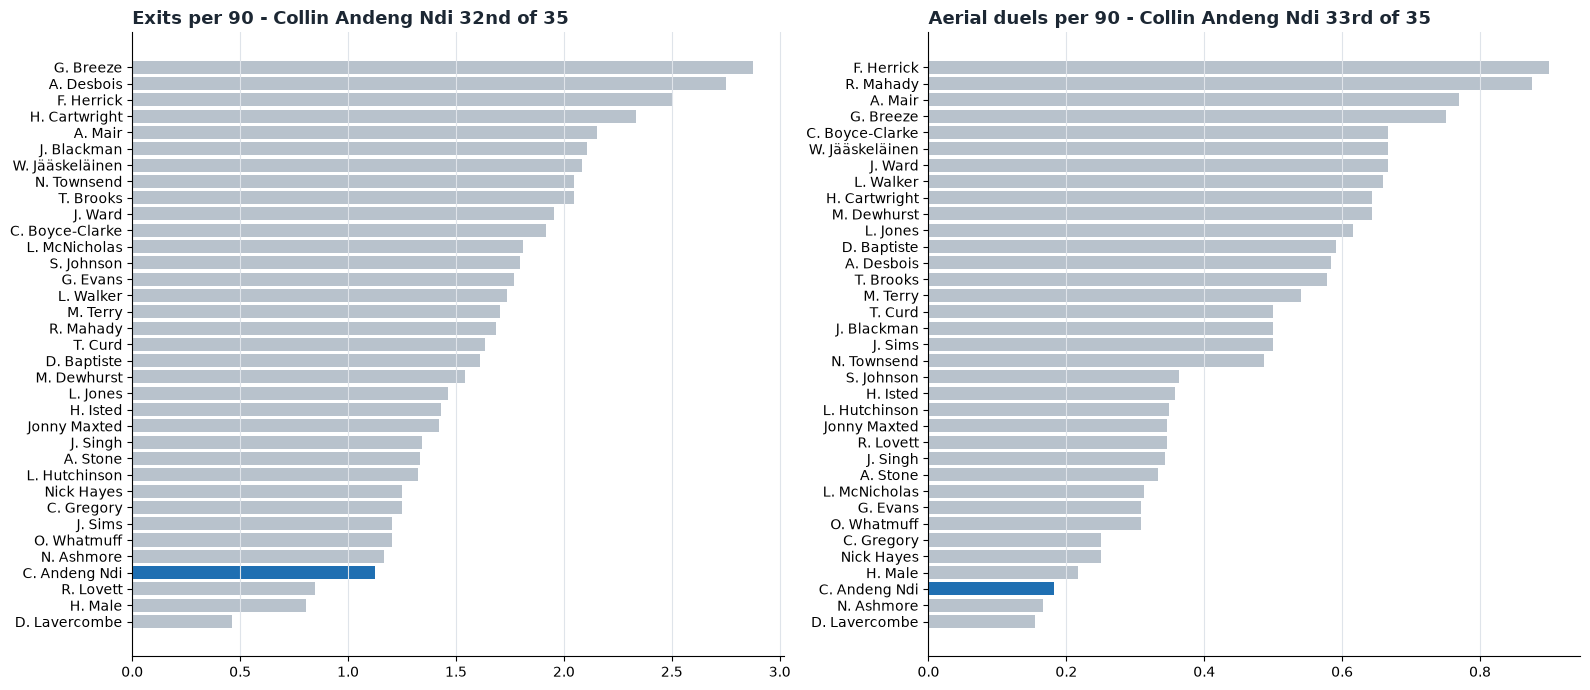

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(16, 7))
for ax, column, label in zip(axs, ["exits_90", "aerials_90"], ["Exits per 90", "Aerial duels per 90"]):
    ordered = table.sort_values(column)
    ax.barh(ordered["keeper"], ordered[column], color=[HIGHLIGHT if k == KEEPER else OTHERS for k in ordered["keeper_id"]])
    ax.set_title(f"{label} - {NAME} {rank_of(table, column)}", loc="left", fontsize=13, weight="bold", color=TEXT)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="x", color=GRID)
plt.tight_layout()
plt.show()

## Summary - where Collin Andeng-Ndi excelled

Ranks are among the 35 National League keepers with 900+ league minutes in 2025/26. Penalties are
left out of the splits. Many of the splits rest on 15-30 shots on target, so one or two saves
either way move a rank a long way. Read them as tendencies, not verdicts.

**Where he was among the best in the league**

* **Headers** - he saved 14 of the 16 headers on target he faced (88% against a league 69%).
  That is 2nd for save % and **1st for goals prevented per shot** among the regular keepers,
  about +3.8 goals over the season.
* **Close range, inside the box** - 6-12 m: 67% saved against a league 58% (6th); 12-18 m: 82%
  against 74% (7th). Together about +4.4 goals prevented. He was good at the reaction saves and
  the one-on-one blocks.
* **Good chances** - against shots of 0.15-0.30 xG he saved 71% (league 63%), 5th best for goals
  prevented per shot.
* **Very long distribution** - 68% of his passes over 60 m found a team mate against a league
  58%. That is **4th of 35**. Over 40 m in total he was 8th (71% against a median 67%), and from free kicks 6th.
  He also went long more often than most: 27% of his passes were over 60 m against 18% for the
  league. Usually a keeper who kicks longer is less accurate. He was both longer *and* more
  accurate, so this is his clearest strength.

**Where he lost goals**

* **Shots from outside the box** - 18-25 m: 70% saved against a league 80% (28th), about -4.2
  goals prevented; 25 m+: 80% against 89%. Most of the goals he "should" have stopped came from
  distance.
* **Speculative chances** - shots of 0.05-0.15 xG: 71% saved against 78%, 32nd of 35. This and
  the long-range shots are the same problem seen two ways.
* **Placement** - he saved all 14 shots at mid height down the middle, and 24 of 27 low
  through the middle. Shots at mid height to the shooter's left (his right) were a weak point:
  4 of 11 saved against a league 64%. He faced only four shots into the top corners and saved
  none.
* **Form** - he was +3.2 goals prevented by 20 January, then lost about 5.4 between late
  January and early April before a small recovery at the end. The goals let in from distance
  are mostly from that spell.

**Overall**

* His save % (70%) was a little above the median (14th), but he faced easier shots than most -
  the 8th-lowest post-shot xG per shot on target - so on goals prevented he was 21st, about
  -1.2 over the season. That is a mid-table number. Most keepers in this division are close to
  zero; the exceptions were Terry at Braintree (+16.6) and Cartwright at Hartlepool (+10.9).
* Southend in front of him allowed only 3.1 shots on target per 90, the 3rd fewest in the league.
  This is why he conceded few goals, more than his shot stopping.
* He was one of the least active keepers off his line: 32nd for exits per 90 and 33rd for
  aerial duels per 90. This can be his style or the team's deep block, but he did not do much
  sweeping or claiming.

**In short:** a strong close-range and aerial shot stopper and one of the most accurate long
kickers in the league, held back by goals let in from distance. If one area should improve,
it is shots from 18 m and further out.